# Notebook 05: Latency and Cost Models

## Objective

This notebook studies latency and resource accounting in quantum-classical computing.

A quantum-cloud workload may contain:
1. Circuit preparation
2. Circuit compilation and transpilation
3. Job submission
4. Cloud queue waiting
5. QPU execution
6. Result retrieval
7. Classical post-processing

\[
T_{total}=T_{prep}+T_{compile}+T_{submit}+T_{queue}+T_{QPU}+T_{return}+T_{post}
\]

We use Qiskit and Qiskit Aer for circuit construction, compilation, local simulation, and profiling. Cloud stages remain unavailable unless actual provider measurements are supplied.

**Important:** Aer wall-clock time is local simulator time, not real QPU execution time or cloud latency.

## 1. Research questions

- How does circuit complexity affect compilation?
- How does shot count affect local simulator execution time?
- How can execution stages be recorded separately?
- How should unavailable cloud measurements be represented?
- How can quantum and classical resources be accounted for?
- How do batch and iterative workloads differ?

This notebook measures local software stages and creates a cloud-timing schema. It does not invent queue times, QPU times, or monetary prices.

In [ ]:
%pip install qiskit qiskit-aer numpy pandas matplotlib

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Define a QAOA Max-Cut workload

We use a three-node triangle graph. Each edge has weight 1. The maximum cut value is 2.

We vary QAOA layer count and shot budget to study local preparation, compilation, simulation, and post-processing.

In [2]:
edges = [(0, 1, 1), (1, 2, 1), (0, 2, 1)]
num_qubits = 3

def calculate_cut_value(assignment):
    return sum(
        weight for u, v, weight in edges
        if assignment[u] != assignment[v]
    )

def decode_bitstring(bitstring):
    return tuple(int(bit) for bit in bitstring.replace(" ", "")[::-1])

def counts_to_samples(counts):
    samples = []
    for bitstring, frequency in counts.items():
        assignment = decode_bitstring(bitstring)
        samples.extend([calculate_cut_value(assignment)] * frequency)
    return np.asarray(samples, dtype=float)

print("Graph defined. Maximum possible cut:", 2)

Graph defined. Maximum possible cut: 2


## 3. Build QAOA circuits

The circuit uses fixed example parameters. The purpose is profiling, not parameter optimization.

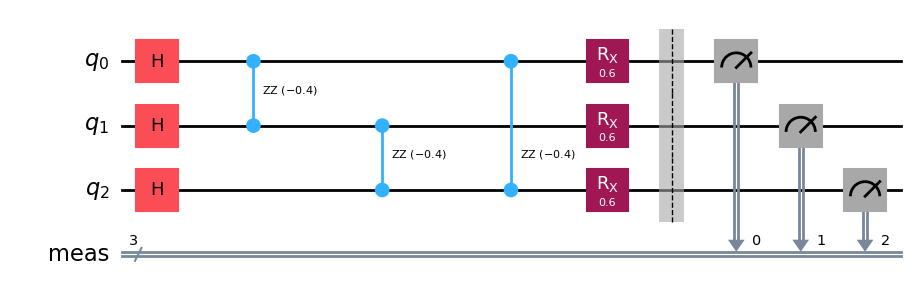

In [3]:
def build_qaoa_circuit(p=1, measure=True):
    qc = QuantumCircuit(num_qubits)
    for qubit in range(num_qubits):
        qc.h(qubit)

    gammas = np.linspace(0.4, 0.8, p)
    betas = np.linspace(0.3, 0.5, p)

    for layer in range(p):
        for u, v, weight in edges:
            qc.rzz(-gammas[layer] * weight, u, v)
        for qubit in range(num_qubits):
            qc.rx(2 * betas[layer], qubit)

    if measure:
        qc.measure_all()
    return qc

circuit_p1 = build_qaoa_circuit(p=1)
display(circuit_p1.draw("mpl"))

## 4. Measure circuit preparation time

`time.perf_counter()` measures local Python wall-clock time. This is not QPU execution time.

In [4]:
def profile_circuit_preparation(p, repetitions=10):
    times = []
    for _ in range(repetitions):
        start = time.perf_counter()
        _ = build_qaoa_circuit(p=p, measure=True)
        times.append(time.perf_counter() - start)

    return {
        "qaoa_layers": p,
        "mean_prep_time_s": np.mean(times),
        "std_prep_time_s": np.std(times, ddof=1),
        "min_prep_time_s": np.min(times),
        "max_prep_time_s": np.max(times)
    }

preparation_df = pd.DataFrame([
    profile_circuit_preparation(p) for p in [1, 2, 3, 4, 5]
])
display(preparation_df)

,qaoa_layers,mean_prep_time_s,std_prep_time_s,min_prep_time_s,max_prep_time_s
0,1,0.000877,0.000713,0.000455,0.002801
1,2,0.000828,0.000283,0.000589,0.001575
2,3,0.000935,0.000413,0.000531,0.001550
3,4,0.001285,0.000588,0.000683,0.002425
4,5,0.000944,0.000628,0.000578,0.002628


## 5. Measure circuit compilation time

We transpile for `AerSimulator`. These are simulator-target compilation measurements, not IBM hardware compilation measurements.

Transpiled depth and gate count describe circuit structure; they are not direct estimates of QPU runtime.

In [5]:
simulator = AerSimulator()

def profile_transpilation(p, repetitions=5):
    circuit = build_qaoa_circuit(p=p, measure=True)
    times = []
    compiled = None

    for _ in range(repetitions):
        start = time.perf_counter()
        compiled = transpile(circuit, simulator, optimization_level=1)
        times.append(time.perf_counter() - start)

    return {
        "qaoa_layers": p,
        "mean_compile_time_s": np.mean(times),
        "std_compile_time_s": np.std(times, ddof=1),
        "compiled_depth": compiled.depth(),
        "compiled_gate_count": compiled.size()
    }

compilation_df = pd.DataFrame([
    profile_transpilation(p) for p in [1, 2, 3, 4, 5]
])
display(compilation_df)

,qaoa_layers,mean_compile_time_s,std_compile_time_s,compiled_depth,compiled_gate_count
0,1,1.018863,1.789182,6,12
1,2,0.228565,0.027848,10,18
2,3,0.388151,0.098915,14,24
3,4,0.278184,0.013499,18,30
4,5,0.258555,0.024182,22,36


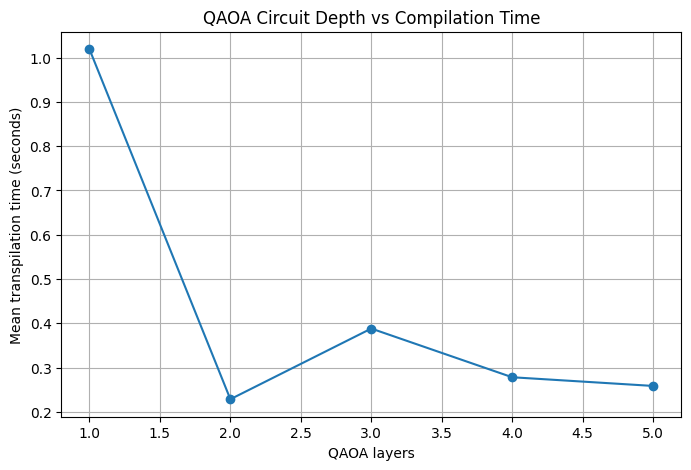

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(compilation_df["qaoa_layers"], compilation_df["mean_compile_time_s"], marker="o")
plt.xlabel("QAOA layers")
plt.ylabel("Mean transpilation time (seconds)")
plt.title("QAOA Circuit Depth vs Compilation Time")
plt.grid(True)
plt.show()

## 6. Measure local simulator execution time

The measured interval includes the local Aer job call and result retrieval as observed by this Python process. It can include simulator and job-handling overhead.

Call this `local_simulator_wall_time_s`, not QPU time.

In [7]:
def profile_simulator_execution(circuit, shots, seed=42):
    compiled = transpile(circuit, simulator, optimization_level=1)

    start = time.perf_counter()
    job = simulator.run(compiled, shots=shots, seed_simulator=seed)
    result = job.result()
    elapsed = time.perf_counter() - start

    counts = result.get_counts()
    return {
        "shots": shots,
        "local_simulator_wall_time_s": elapsed,
        "measurement_outcomes": sum(counts.values()),
        "unique_outcomes": len(counts),
        "counts": counts
    }

shot_budgets = [100, 500, 1000, 2000, 5000, 10000]
profiling_circuit = build_qaoa_circuit(p=2, measure=True)

simulator_results = [
    profile_simulator_execution(profiling_circuit, shots, seed=100 + shots)
    for shots in shot_budgets
]
simulator_df = pd.DataFrame(simulator_results)
display(simulator_df.drop(columns=["counts"]))

,shots,local_simulator_wall_time_s,measurement_outcomes,unique_outcomes
0,100,0.020712,100,8
1,500,0.004331,500,8
2,1000,0.007215,1000,8
3,2000,0.034049,2000,8
4,5000,0.018892,5000,8
5,10000,0.037958,10000,8


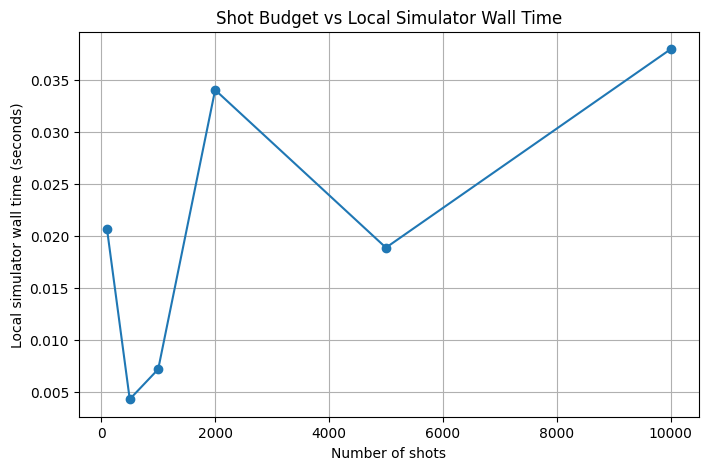

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(simulator_df["shots"], simulator_df["local_simulator_wall_time_s"], marker="o")
plt.xlabel("Number of shots")
plt.ylabel("Local simulator wall time (seconds)")
plt.title("Shot Budget vs Local Simulator Wall Time")
plt.grid(True)
plt.show()

## 7. Measure classical post-processing time

For Max-Cut, we calculate estimated expected cut, sample variance, standard error, best observed cut, and empirical probability of an optimal cut.

In [9]:
def profile_postprocessing(counts):
    start = time.perf_counter()
    samples = counts_to_samples(counts)

    expected_cut = np.mean(samples)
    variance = np.var(samples, ddof=1) if len(samples) > 1 else np.nan
    standard_error = np.sqrt(variance / len(samples)) if len(samples) > 1 else np.nan

    result = {
        "postprocessing_time_s": None,
        "shots": len(samples),
        "expected_cut": expected_cut,
        "sample_variance": variance,
        "standard_error": standard_error,
        "best_observed_cut": np.max(samples),
        "optimal_solution_probability": np.mean(samples == 2)
    }
    result["postprocessing_time_s"] = time.perf_counter() - start
    return result

postprocessing_df = pd.DataFrame([
    profile_postprocessing(counts) for counts in simulator_df["counts"]
])
display(postprocessing_df)

,postprocessing_time_s,shots,expected_cut,sample_variance,standard_error,best_observed_cut,optimal_solution_probability
0,0.000576,100,1.1400,0.990303,0.099514,2.0,0.5700
1,0.000309,500,1.1480,0.980056,0.044273,2.0,0.5740
2,0.000376,1000,1.1280,0.984601,0.031378,2.0,0.5640
3,0.000517,2000,1.1350,0.982266,0.022162,2.0,0.5675
4,0.000812,5000,1.1532,0.976725,0.013977,2.0,0.5766
5,0.001652,10000,1.1550,0.976073,0.009880,2.0,0.5775


## 8. Separate local and cloud timing

A local simulator does not have the same pipeline as a cloud QPU.

**Local Aer:** circuit preparation, local transpilation, local simulator execution, local result processing.

**Cloud QPU:** circuit preparation, hardware-target compilation, submission, provider queue, QPU execution, result retrieval, and classical post-processing.

Providers may expose only some stages. Record measured or provider-reported values only. Keep unavailable stages as `None`.

In [10]:
cloud_timing_record = {
    "backend": None,
    "execution_type": "Cloud QPU",
    "preparation_time_s": None,
    "compilation_time_s": None,
    "submission_time_s": None,
    "queue_time_s": None,
    "qpu_time_s": None,
    "result_return_time_s": None,
    "postprocessing_time_s": None,
    "total_cloud_latency_s": None,
    "measurement_status": "NOT_MEASURED"
}

cloud_timing_df = pd.DataFrame([cloud_timing_record])
display(cloud_timing_df)

,backend,execution_type,preparation_time_s,compilation_time_s,submission_time_s,queue_time_s,qpu_time_s,result_return_time_s,postprocessing_time_s,total_cloud_latency_s,measurement_status
0,None,Cloud QPU,None,None,None,None,None,None,None,None,NOT_MEASURED


In [11]:
CLOUD_STAGES = [
    "preparation_time_s", "compilation_time_s", "submission_time_s",
    "queue_time_s", "qpu_time_s", "result_return_time_s",
    "postprocessing_time_s"
]

def calculate_total_latency(record):
    values = [record.get(stage) for stage in CLOUD_STAGES]

    for stage, value in zip(CLOUD_STAGES, values):
        if value is not None and value < 0:
            raise ValueError(f"{stage} cannot be negative.")

    if any(value is None for value in values):
        return {"total_latency_s": None, "status": "INCOMPLETE_MEASUREMENTS"}

    return {"total_latency_s": sum(values), "status": "COMPLETE"}

print(calculate_total_latency(cloud_timing_record))

{'total_latency_s': None, 'status': 'INCOMPLETE_MEASUREMENTS'}


## 9. Resource accounting

Track quantum-related and classical metrics separately.

Quantum-related metrics may include shots, circuit executions, submitted jobs, and provider-reported QPU time.

Classical metrics may include preparation, compilation, post-processing, CPU time, and memory usage.

Monetary cost must only be calculated when actual provider pricing and usage records are available. This notebook does not invent prices.

In [12]:
last_simulator_row = simulator_df.iloc[-1]
last_postprocessing_row = postprocessing_df.iloc[-1]

resource_record = {
    "execution_type": "Local Aer",
    "shots": int(last_simulator_row["shots"]),
    "circuit_executions": 1,
    "qpu_time_s": None,
    "local_simulator_wall_time_s": float(last_simulator_row["local_simulator_wall_time_s"]),
    "postprocessing_time_s": float(last_postprocessing_row["postprocessing_time_s"]),
    "quantum_monetary_cost": None,
    "classical_monetary_cost": None,
    "network_monetary_cost": None,
    "total_monetary_cost": None
}

resource_df = pd.DataFrame([resource_record])
display(resource_df)

,execution_type,shots,circuit_executions,qpu_time_s,local_simulator_wall_time_s,postprocessing_time_s,quantum_monetary_cost,classical_monetary_cost,network_monetary_cost,total_monetary_cost
0,Local Aer,10000,1,None,0.037958,0.001652,None,None,None,None


## 10. Batch and iterative execution patterns

**Batch execution:** independent circuits may be grouped into a batch, subject to provider support. End-to-end batch latency is not necessarily the sum of individual task latencies.

**Iterative execution:** algorithms such as VQE and many QAOA workflows repeatedly execute circuits, process results, and update classical parameters.

The following experiment demonstrates repeated local execution. It increases QAOA layer count each round; it is an execution-structure demonstration, not a complete parameter-optimizing QAOA/VQE algorithm.

In [13]:
def run_iterative_local_experiment(rounds=5, shots=1000):
    round_records = []

    for round_id in range(1, rounds + 1):
        circuit = build_qaoa_circuit(p=round_id, measure=True)
        execution = profile_simulator_execution(
            circuit, shots=shots, seed=1000 + round_id
        )
        postprocessing = profile_postprocessing(execution["counts"])

        round_records.append({
            "round": round_id,
            "qaoa_layers": round_id,
            "shots": shots,
            "local_simulator_wall_time_s": execution["local_simulator_wall_time_s"],
            "postprocessing_time_s": postprocessing["postprocessing_time_s"],
            "expected_cut": postprocessing["expected_cut"]
        })

    return pd.DataFrame(round_records)

iterative_df = run_iterative_local_experiment(rounds=5, shots=1000)
display(iterative_df)

,round,qaoa_layers,shots,local_simulator_wall_time_s,postprocessing_time_s,expected_cut
0,1,1,1000,0.006055,0.000951,1.948
1,2,2,1000,0.006758,0.000912,1.180
2,3,3,1000,0.009026,0.000713,1.668
3,4,4,1000,0.008318,0.000785,1.702
4,5,5,1000,0.008332,0.001415,1.228


In [ ]:
print("Sum of local simulator wall times (s):",
      iterative_df["local_simulator_wall_time_s"].sum())
print("Sum of post-processing times (s):",
      iterative_df["postprocessing_time_s"].sum())
print("Total measurement shots:", iterative_df["shots"].sum())

## 11. General latency calculator

For a single execution:

\[
T_{total}=T_{prep}+T_{compile}+T_{submit}+T_{queue}+T_{QPU}+T_{return}+T_{post}
\]

For iterative execution:

\[
T_{iterative}=\sum_{k=1}^{K}T_{round,k}+\sum_{k=1}^{K-1}T_{decision,k}
\]

Do not assume batch latency is the sum of individual task latencies. Measure actual end-to-end behavior where possible.

In [14]:
def calculate_latency(
    preparation=None,
    compilation=None,
    submission=None,
    queue=None,
    qpu=None,
    result_return=None,
    postprocessing=None
):
    stages = {
        "preparation": preparation,
        "compilation": compilation,
        "submission": submission,
        "queue": queue,
        "qpu": qpu,
        "result_return": result_return,
        "postprocessing": postprocessing
    }

    for name, value in stages.items():
        if value is not None and value < 0:
            raise ValueError(f"{name} cannot be negative.")

    available = [value for value in stages.values() if value is not None]
    missing = [name for name, value in stages.items() if value is None]

    if missing:
        return {
            "total_latency_s": None,
            "available_stage_sum_s": sum(available),
            "missing_stages": missing,
            "status": "INCOMPLETE"
        }

    return {
        "total_latency_s": sum(available),
        "available_stage_sum_s": sum(available),
        "missing_stages": [],
        "status": "COMPLETE"
    }

example = calculate_latency(
    preparation=0.02,
    compilation=0.15,
    submission=None,
    queue=None,
    qpu=None,
    result_return=None,
    postprocessing=0.01
)
print(example)

{'total_latency_s': None, 'available_stage_sum_s': 0.18, 'missing_stages': ['submission', 'queue', 'qpu', 'result_return'], 'status': 'INCOMPLETE'}


## 12. Research interpretation

### Observation 1: Circuit complexity
Circuit depth and gate count describe circuit structure. Compilation time may vary with circuit structure and compiler configuration.

### Observation 2: Shot count
Local simulator wall time may change with shot count, circuit structure, simulator configuration, and local system load.

### Observation 3: Classical processing
Post-processing and parameter updates contribute to end-to-end application latency.

### Observation 4: Cloud observability
A runtime may not observe every provider stage. Missing queue or QPU timing values must remain unavailable.

### Observation 5: Resource accounting
Shot count, circuit executions, local processing time, provider-reported QPU time, and monetary cost are distinct metrics.

## Limitations

1. Aer timings are local simulator measurements.
2. No real cloud submission or queue measurement is performed.
3. No actual QPU execution time is reported.
4. No monetary cost is calculated without provider pricing data.
5. The iterative experiment demonstrates execution structure, not a complete variational optimizer.
6. Results depend on the local computer and execution environment.

## 13. Save experimental results

CSV files are saved in the notebook's current working directory.

In [ ]:
preparation_df.to_csv("notebook05_preparation_results.csv", index=False)
compilation_df.to_csv("notebook05_compilation_results.csv", index=False)
simulator_df.drop(columns=["counts"]).to_csv("notebook05_simulator_results.csv", index=False)
postprocessing_df.to_csv("notebook05_postprocessing_results.csv", index=False)
cloud_timing_df.to_csv("notebook05_cloud_timing_template.csv", index=False)
resource_df.to_csv("notebook05_resource_accounting.csv", index=False)
iterative_df.to_csv("notebook05_iterative_results.csv", index=False)

print("Notebook 05 experimental results saved.")

## 14. Completion checklist

- [ ] Built QAOA circuits using Qiskit.
- [ ] Measured circuit preparation time.
- [ ] Measured simulator-target transpilation time.
- [ ] Compared compiled circuit depth and gate count.
- [ ] Measured local Aer simulator wall time.
- [ ] Compared different shot budgets.
- [ ] Measured classical post-processing time.
- [ ] Created a separate cloud timing record.
- [ ] Implemented incomplete-measurement handling.
- [ ] Created a quantum and classical resource record.
- [ ] Explored iterative workload execution.
- [ ] Implemented a general latency calculator.
- [ ] Saved experimental results.

## Final research takeaway

A quality-aware quantum-classical runtime must consider more than the time spent executing a quantum circuit. It should measure and account for the execution pipeline, classical processing, and available quantum resource data.

Accurate stage-level measurements provide the foundation for latency-aware execution decisions in QFlowPilot.